Using code from the CCD lab: 

In [1]:
import os
from astropy.io import fits
from astropy.wcs import WCS
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import scoreatpercentile
import glob
%matplotlib inline
from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [2]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

In [3]:
datadir = '/home/nathaniel-sexton/ASTR596/Data/Capstone' ## NOTE: will need to change this if going to a different machine! 

#change directory to the data directory
os.chdir(datadir)

Text(0.5, 1.0, 'Science Frame - NGC 1232')

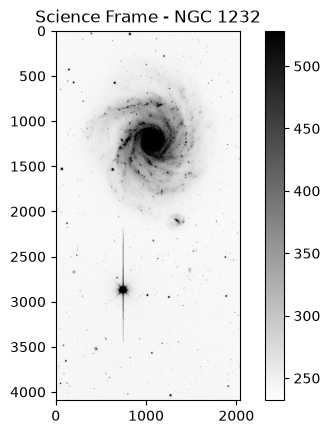

In [4]:
## display an image: 
## using the image at https://www.legacysurvey.org/viewer/image-data/ls-dr11-south/decam-698894-S8-r
plt.figure() 
scienceFrame, scienceFrame_header = fits.getdata('image-decam-698894-S8-r.fits.fits', header=True)
imdisplay(scienceFrame, v2perc=99)
plt.title("Science Frame - NGC 1232") 


grabbing a subsection of this frame:

Text(0.5, 1.0, 'Science Frame Slice')

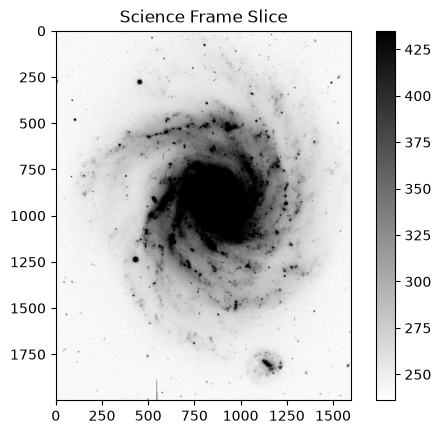

In [5]:
## defining bounds of image slice:

rowStart = 300 -1 
rowEnd = 2300 - 1 ## subtract 1 for indexing (arrays start at 0) 

columnsStart = 200 - 1 
columnsEnd = 1800 - 1 

## create slice variable: 
imgSlice = scienceFrame[rowStart:rowEnd, columnsStart:columnsEnd]
## create plot using display code from cell 17: 
plt.figure() ## create figure object

imdisplay(imgSlice) ## display data 
plt.title("Science Frame Slice") ## name plot 

Printing some header keywords: 

In [15]:
print("(xref, yref) : (", scienceFrame_header['CRPIX1'], ', ',  scienceFrame_header['CRPIX2'], ')' )
print("RAref, DECref: ", scienceFrame_header['CRVAL1'], ', ',  scienceFrame_header['CRVAL2'])

(xref, yref) : ( 4404.60000000001 ,  12695.33 )
RAref, DECref:  48.33340414163 ,  -20.82436019943
